# Who Does the Ad Actually Work On? An Uplift Model


The A/B test showed the ad works on average: 2.55% conversion vs 1.79%. But an average can hide a lot. Maybe the ad works strongly on some users and does nothing for everyone else. If so, a business could show the ad only to the users it helps and save the rest of the ad budget.

That is what an uplift model answers. Instead of predicting will this user convert, it predicts how much does showing the ad change this user's chance of converting.

Method (T learner): train two logistic regression models, using the same from scratch code as my conversion model notebook.

- Model T learns P(convert) using only users who saw the ad
- Model C learns P(convert) using only users who saw the PSA
- For each user: uplift = P(convert | ad) − P(convert | PSA)

Then I check, on users the models never saw, whether the users ranked highest really do respond more to the ad.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

## Step 1: Look before modeling

Before building anything, I split users into five equal groups by how many ads they saw and compare the two test groups inside each. If the ad effect is the same for everyone, the gap should look similar in every row.

In [2]:
df = pd.read_csv('marketing_AB.csv').drop(columns=['Unnamed: 0'])
df['exposure_group'] = pd.qcut(df['total ads'], 5, duplicates='drop')

look = df.groupby(['exposure_group', 'test group'], observed=True)['converted'].mean().unstack()
look['gap (ad minus psa)'] = look['ad'] - look['psa']
print((look * 100).round(2).astype(str) + ' %')

test group          ad     psa gap (ad minus psa)
exposure_group                                   
(0.999, 3.0]    0.21 %  0.18 %             0.03 %
(3.0, 8.0]      0.38 %  0.54 %            -0.16 %
(8.0, 17.0]     0.73 %  0.73 %              0.0 %
(17.0, 33.0]    1.72 %  1.63 %             0.09 %
(33.0, 2065.0]  9.83 %  6.03 %              3.8 %


Almost the whole effect sits in the top group. For users who saw the most ads, the ad group converts far more than the PSA group. In every other group the gap is close to zero.

This is a strong hint that the effect is not spread evenly, which is exactly the situation where an uplift model is useful.

## Step 2: Features and split

The features are the same as the conversion model, except test group, because test group is now the thing whose effect I am measuring, not an input.

I split 50/50 into train and test. The PSA group is small (about 23,500 users and only 420 conversions in total), so I keep a large test half to make the evaluation less noisy. The split is stratified on both test group and conversion so each half keeps the same mix.

In [3]:
y = df['converted'].astype(int).values
t = (df['test group'] == 'ad').astype(int).values

X = pd.DataFrame({
    'log_total_ads': np.log1p(df['total ads']),
    'hour_sin': np.sin(2 * np.pi * df['most ads hour'] / 24),
    'hour_cos': np.cos(2 * np.pi * df['most ads hour'] / 24),
})
X = pd.concat([X, pd.get_dummies(df['most ads day'], prefix='day', drop_first=True).astype(int)], axis=1)
X = X.values.astype(float)

strata = t * 2 + y
X_train, X_test, y_train, y_test, t_train, t_test = train_test_split(
    X, y, t, test_size=0.5, stratify=strata, random_state=42)

mu, sd = X_train.mean(axis=0), X_train.std(axis=0)
def phi(A):
    return np.hstack([np.ones((len(A), 1)), (A - mu) / sd])
P_train, P_test = phi(X_train), phi(X_test)

print('Train ad users :', (t_train == 1).sum(), '  Train PSA users:', (t_train == 0).sum())
print('Test ad users  :', (t_test == 1).sum(), '  Test PSA users :', (t_test == 0).sum())

Train ad users : 282288   Train PSA users: 11762
Test ad users  : 282289   Test PSA users : 11762


## Step 3: Train the two models

Same from scratch logistic regression as before: sigmoid, BCE gradient, mini batch SGD. Cross validation in the conversion model showed regularization was not needed with this few features, so λ = 0.

In [4]:
def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -30, 30)))

def train_logreg(P, y, lam=0.0, lr=1.0, epochs=25, batch_size=2048, seed=0):
    rng = np.random.default_rng(seed)
    w = np.zeros(P.shape[1])
    n = len(y)
    for epoch in range(epochs):
        step = lr / (1 + 0.1 * epoch)
        order = rng.permutation(n)
        for start in range(0, n, batch_size):
            b = order[start:start + batch_size]
            grad = -(P[b].T @ (y[b] - sigmoid(P[b] @ w))) / len(b)
            reg = lam * w
            reg[0] = 0
            w -= step * (grad + reg)
    return w

w_ad = train_logreg(P_train[t_train == 1], y_train[t_train == 1])
w_psa = train_logreg(P_train[t_train == 0], y_train[t_train == 0])

uplift = sigmoid(P_test @ w_ad) - sigmoid(P_test @ w_psa)
print('Predicted uplift, 5th to 95th percentile:', np.percentile(uplift, [5, 25, 50, 75, 95]).round(4))

Predicted uplift, 5th to 95th percentile: [-0.0141 -0.0112 -0.0085 -0.0054  0.0374]


## Step 4: Does the ranking hold up on new users?

This is the real test. I rank the **test** users from highest to lowest predicted uplift and cut them into 10 equal groups (deciles). Inside each decile I measure the *actual* conversion rate of ad users and PSA users. Because users were randomly assigned to ad or PSA, the actual gap inside each decile is a fair estimate of the true effect there.

If the model works, decile 1 should show the biggest real gap, and the gap should shrink as we go down.

          users  ad_rate_%  psa_rate_%  psa_users  real_uplift_pts
decile                                                            
1       29406.0      14.37        8.21     1218.0             6.16
2       29405.0       4.77        2.62     1145.0             2.15
3       29405.0       1.09        1.02     1171.0             0.07
4       29405.0       0.69        0.41     1209.0             0.27
5       29405.0       0.63        0.71     1269.0            -0.08
6       29405.0       0.71        0.58     1207.0             0.13
7       29405.0       0.86        0.86     1167.0             0.00
8       29405.0       0.72        1.19     1097.0            -0.46
9       29405.0       0.83        1.24     1129.0            -0.41
10      29405.0       0.90        0.87     1150.0             0.03


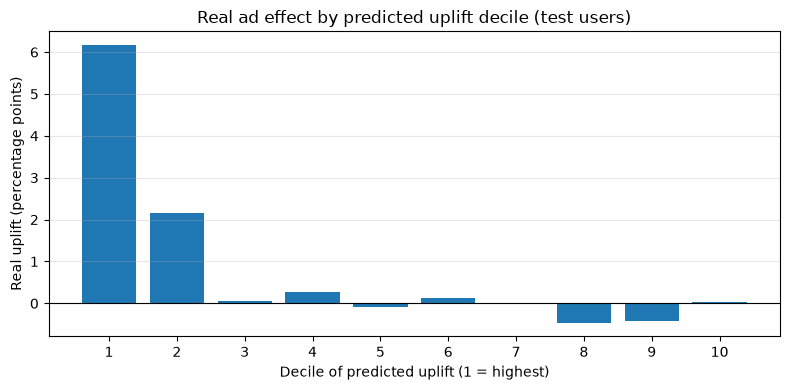

In [5]:
d = pd.DataFrame({'uplift': uplift, 'y': y_test, 't': t_test})
d['decile'] = pd.qcut(d['uplift'].rank(method='first', ascending=False), 10, labels=range(1, 11))

def decile_stats(s):
    return pd.Series({
        'users': len(s),
        'ad_rate_%': 100 * s.loc[s.t == 1, 'y'].mean(),
        'psa_rate_%': 100 * s.loc[s.t == 0, 'y'].mean(),
        'psa_users': (s.t == 0).sum(),
    })

table = d.groupby('decile', observed=True).apply(decile_stats)
table['real_uplift_pts'] = table['ad_rate_%'] - table['psa_rate_%']
print(table.round(2).to_string())

plt.figure(figsize=(8, 4))
plt.bar(table.index.astype(int), table['real_uplift_pts'])
plt.axhline(0, color='black', linewidth=0.8)
plt.xticks(range(1, 11))
plt.xlabel('Decile of predicted uplift (1 = highest)')
plt.ylabel('Real uplift (percentage points)')
plt.title('Real ad effect by predicted uplift decile (test users)')
plt.grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.savefig('uplift_by_decile.png', dpi=120)
plt.show()

## Step 5: How much of the ad's value sits at the top?

This curve, often called a **Qini curve**, answers a practical question: if I show the ad only to the top X% of users by predicted uplift, what share of all the extra conversions do I keep?

The dashed line is random targeting. Showing the ad to a random 20% of users keeps about 20% of the extra conversions. The further the model's curve sits above that line, the better it is at finding the users the ad actually helps.

Targeting top 10% of users keeps 80% of extra conversions
Targeting top 20% of users keeps 106% of extra conversions
Targeting top 30% of users keeps 106% of extra conversions
Targeting top 50% of users keeps 111% of extra conversions


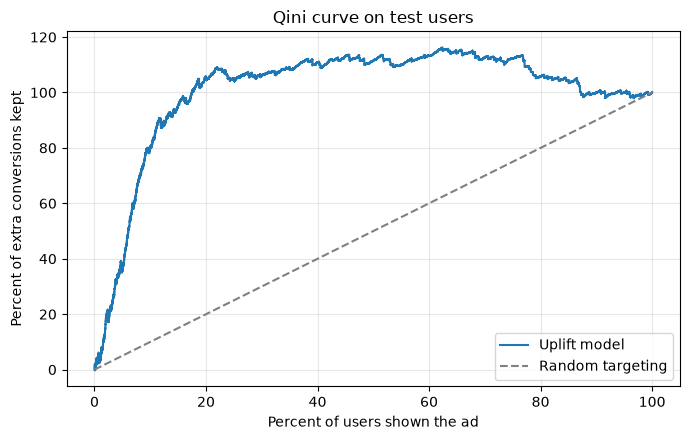

In [6]:
d = d.sort_values('uplift', ascending=False).reset_index(drop=True)
cum_t = np.cumsum(d['t'])
cum_c = np.cumsum(1 - d['t'])
cum_yt = np.cumsum(d['y'] * d['t'])
cum_yc = np.cumsum(d['y'] * (1 - d['t']))
incremental = cum_yt - cum_yc * cum_t / np.maximum(cum_c, 1)
total = incremental.iloc[-1]
share = np.arange(1, len(d) + 1) / len(d)

for frac in [0.10, 0.20, 0.30, 0.50]:
    k = int(frac * len(d)) - 1
    print(f'Targeting top {frac:.0%} of users keeps {incremental.iloc[k] / total:.0%} of extra conversions')

plt.figure(figsize=(7, 4.5))
plt.plot(share * 100, incremental / total * 100, label='Uplift model')
plt.plot([0, 100], [0, 100], linestyle='--', color='gray', label='Random targeting')
plt.xlabel('Percent of users shown the ad')
plt.ylabel('Percent of extra conversions kept')
plt.title('Qini curve on test users')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('uplift_qini_curve.png', dpi=120)
plt.show()

The curve can rise above 100% because some lower deciles have a slightly *negative* real effect. Adding those users back actually costs a few conversions, so stopping early keeps more than the full total. Those small negative gaps are most likely noise from the small PSA group, not proof the ad hurts anyone.

## Step 6: Is the difference real, or just noise?

The PSA group in each decile is small, so I check stability with a **bootstrap**: resample the test users with replacement 300 times, and each time measure the real ad effect in the top 20% minus the effect in the other 80%. If the 95% range stays clearly above zero, the difference is not a fluke.

In [7]:
top = d.iloc[:int(0.2 * len(d))]
rest = d.iloc[int(0.2 * len(d)):]

def real_lift(s):
    return s.loc[s.t == 1, 'y'].mean() - s.loc[s.t == 0, 'y'].mean()

boot = []
for i in range(300):
    a = top.sample(len(top), replace=True, random_state=i)
    b = rest.sample(len(rest), replace=True, random_state=i)
    boot.append(real_lift(a) - real_lift(b))
low, high = np.percentile(boot, [2.5, 97.5])

print(f'Real ad effect, top 20%  : {100 * real_lift(top):.2f} percentage points')
print(f'Real ad effect, other 80%: {100 * real_lift(rest):.2f} percentage points')
print(f'Difference, 95% bootstrap range: {100 * low:.2f} to {100 * high:.2f} points')

Real ad effect, top 20%  : 4.07 percentage points
Real ad effect, other 80%: -0.05 percentage points
Difference, 95% bootstrap range: 3.21 to 5.01 points


## What this tells us

1. The ad's effect is concentrated. On users the models never saw, the top 10% by predicted uplift account for most of the extra conversions, and the top 20% account for essentially all of them. For the remaining 80%, the real effect is about zero.
2. The result is stable. The bootstrap range for the top 20% vs everyone else stays well above zero, so this is not noise.
3. Ranking matters more than the raw numbers. Many predicted uplift values are slightly negative, because the PSA model is trained on few users and is less precise. What matters is the *order*, and the decile check shows the order is right.

Business recommendation: instead of showing the ad to everyone, a team could focus ad spend on the high uplift segment, keeping nearly all the incremental conversions at a fraction of the cost.

Honest limitation: the main driver is how many ads a user saw, which is measured *during* the experiment. Engaged users see more ads, so in real targeting this feature would not be known in advance. A production version would need a feature known before the campaign, such as past site visits or past purchases. I state this plainly because a targeting rule built on a feature you cannot see ahead of time would not work in practice.